# Curve fitting with Bayesian Ridge Regression: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/linear_model/plot_bayesian_ridge_curvefit.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/linear_model/plot_bayesian_ridge_curvefit.html)).

**Scenario:** a cubic polynomial (Vandermonde features) is fitted to 25 noisy samples of sin(2πx) with `BayesianRidge(tol=1e-6, fit_intercept=False, compute_score=True)`. The first fit uses the default initial precisions. The same estimator is then refitted after `set_params(alpha_init=1.0, lambda_init=1e-3)`. Each fit reports the posterior mean and standard deviation from `predict(X_test, return_std=True)`, the learned `alpha_` and `lambda_`, and the final log marginal likelihood `scores_[-1]`.

**Adaptations:**
- The data is generated by the official NumPy code and shared with Mojo.
- `predict(X, return_std=True)` returns a `Variant`. The Mojo cell uses the typed `predict_std(X)`, which returns the (mean, std) tuple directly; both are documented in `families/linear_model/algorithms/bayesian/docs/api.md`.
- Keyword `set_params` takes `Optional[Optional[Float64]]` for `alpha_init`/`lambda_init` (documented there).
- Beyond the example, the notebook also checks a Float32 fit, `sigma_`, `n_iter_`, the full `scores_` history and a `clone` of the fitted model.

**Determinism:** deterministic. The data is seeded, and the evidence maximization is a fixed-point iteration with an SVD solve.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("linear_model/plot_bayesian_ridge_curvefit")

## 1. scikit-learn (Python reference, official code)

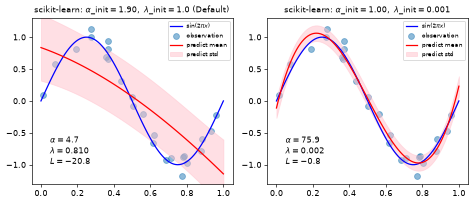

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import BayesianRidge


def func(x):
    return np.sin(2 * np.pi * x)


size = 25
rng = np.random.RandomState(1234)
x_train = rng.uniform(0.0, 1.0, size)
y_train = func(x_train) + rng.normal(scale=0.1, size=size)
x_test = np.linspace(0.0, 1.0, 100)

n_order = 3
X_train = np.vander(x_train, n_order + 1, increasing=True)
X_test = np.vander(x_test, n_order + 1, increasing=True)
reg = BayesianRidge(tol=1e-6, fit_intercept=False, compute_score=True)

sk = []
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), dpi=60)
for i, ax in enumerate(axes):
    # Bayesian ridge regression with different initial value pairs
    if i == 0:
        init = [1 / np.var(y_train), 1.0]  # Default values
    elif i == 1:
        init = [1.0, 1e-3]
        reg.set_params(alpha_init=init[0], lambda_init=init[1])
    reg.fit(X_train, y_train)
    ymean, ystd = reg.predict(X_test, return_std=True)
    sk.append(dict(mean=ymean, std=ystd, alpha=reg.alpha_, lambda_=reg.lambda_, scores=reg.scores_.copy(),
                   coef=reg.coef_.copy(), sigma=reg.sigma_.copy(), n_iter=reg.n_iter_))

    ax.plot(x_test, func(x_test), color="blue", label="sin($2\\pi x$)")
    ax.scatter(x_train, y_train, s=50, alpha=0.5, label="observation")
    ax.plot(x_test, ymean, color="red", label="predict mean")
    ax.fill_between(x_test, ymean - ystd, ymean + ystd, color="pink", alpha=0.5, label="predict std")
    ax.set_ylim(-1.3, 1.3)
    ax.legend(fontsize=7)
    title = "$\\alpha$_init$={:.2f},\\ \\lambda$_init$={}$".format(init[0], init[1])
    if i == 0:
        title += " (Default)"
    ax.set_title("scikit-learn: " + title, fontsize=10)
    text = "$\\alpha={:.1f}$\n$\\lambda={:.3f}$\n$L={:.1f}$".format(reg.alpha_, reg.lambda_, reg.scores_[-1])
    ax.text(0.05, -1.0, text, fontsize=10)
plt.tight_layout()
plt.show()
reg32 = BayesianRidge(tol=1e-6, fit_intercept=False, compute_score=True).fit(X_train.astype(np.float32),
                                                                          y_train.astype(np.float32))
sk32_mean, sk32_std = reg32.predict(X_test.astype(np.float32), return_std=True)
nb.share(X_train=X_train, y_train=y_train, X_test=X_test)

## 2. Moxie (native Mojo)

In [3]:
%%mojo bayesian_ridge
from numojo import NDArray
from moxie.base import clone
from moxie.linear_model import BayesianRidge
from moxie_nb_io import load, save, save_floats, save_ints


def main() raises:
    var X_train = load("X_train")
    var y_train = load("y_train")
    var X_test = load("X_test")
    var reg = BayesianRidge(tol=1e-6, fit_intercept=False, compute_score=True)
    for i in range(2):
        if i == 1:
            _ = reg.set_params(alpha_init=Optional[Optional[Float64]](Optional[Float64](1.0)),
                               lambda_init=Optional[Optional[Float64]](Optional[Float64](1e-3)))
        _ = reg.fit(X_train, y_train)
        var posterior = reg.predict_std(X_test)
        var tag = String("fit") + String(i)
        save(tag + "_mean", posterior[0])
        save(tag + "_std", posterior[1])
        save(tag + "_plain_predict", reg.predict(X_test))
        save_floats(tag + "_precisions", [reg.alpha_, reg.lambda_])
        save(tag + "_scores", reg.scores_)
        save(tag + "_coef", reg.coef_)
        save(tag + "_sigma", reg.sigma_)
        save_ints(tag + "_n_iter", [reg.n_iter_])
    var copy = clone(reg)
    print("clone is unfitted:", not copy.__sklearn_is_fitted__(),
          "| clone keeps lambda_init:", copy.lambda_init.value())

    var reg32 = BayesianRidge[DType.float32](tol=1e-6, fit_intercept=False, compute_score=True)
    _ = reg32.fit(X_train.astype[DType.float32](), y_train.astype[DType.float32]())
    var posterior32 = reg32.predict_std(X_test.astype[DType.float32]())
    save("f32_mean", posterior32[0])
    save("f32_std", posterior32[1])

clone is unfitted: True | clone keeps lambda_init: 0.001


## 3. Side by side and parity

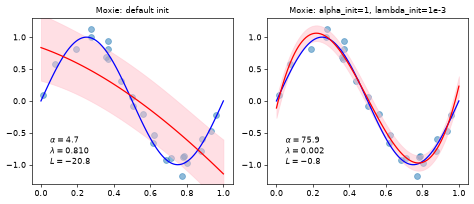

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
default init: predict mean,PASS,"(100,)","(100,)",2.22e-15,1.23e-13,"rtol=1e-07, atol=1e-09",,"Float64 on both sides; the posterior is solved from an SVD (LAPACK in sklearn, Jacobi SVD in Moxie), so only factorization rounding differs. The Vandermonde basis has cond ~ 1e2, and the family parity bound is 1e-7"
default init: predict std,PASS,"(100,)","(100,)",3.33e-16,6.34e-16,"rtol=1e-07, atol=1e-09",,"Float64 on both sides; the posterior is solved from an SVD (LAPACK in sklearn, Jacobi SVD in Moxie), so only factorization rounding differs. The Vandermonde basis has cond ~ 1e2, and the family parity bound is 1e-7"
default init: predict(X) without std,PASS,"(100,)","(100,)",2.22e-15,1.23e-13,"rtol=1e-07, atol=1e-09",,"Float64 on both sides; the posterior is solved from an SVD (LAPACK in sklearn, Jacobi SVD in Moxie), so only factorization rounding differs. The Vandermonde basis has cond ~ 1e2, and the family parity bound is 1e-7"
"default init: alpha_, lambda_",PASS,"(2,)","(2,)",5.55e-16,6.86e-16,"rtol=1e-07, atol=0",,"Float64 on both sides; the posterior is solved from an SVD (LAPACK in sklearn, Jacobi SVD in Moxie), so only factorization rounding differs. The Vandermonde basis has cond ~ 1e2, and the family parity bound is 1e-7"
default init: coef_,PASS,"(4,)","(4,)",3.39e-15,2.47e-14,"rtol=1e-07, atol=1e-09",,"Float64 on both sides; the posterior is solved from an SVD (LAPACK in sklearn, Jacobi SVD in Moxie), so only factorization rounding differs. The Vandermonde basis has cond ~ 1e2, and the family parity bound is 1e-7"
default init: sigma_,PASS,"(4, 4)","(4, 4)",8.88e-16,1.74e-15,"rtol=1e-07, atol=1e-09",,"Float64 on both sides; the posterior is solved from an SVD (LAPACK in sklearn, Jacobi SVD in Moxie), so only factorization rounding differs. The Vandermonde basis has cond ~ 1e2, and the family parity bound is 1e-7"
default init: scores_ (log marginal likelihood history),PASS,"(24,)","(24,)",3e-09,1.38e-10,"rtol=1e-07, atol=0",,"Float64 on both sides; the posterior is solved from an SVD (LAPACK in sklearn, Jacobi SVD in Moxie), so only factorization rounding differs. The Vandermonde basis has cond ~ 1e2, and the family parity bound is 1e-7"
default init: n_iter_,PASS,(),(),,,exact,0 mismatches,
"after set_params(alpha_init=1, lambda_init=1e-3): predict mean",PASS,"(100,)","(100,)",1.42e-14,1.53e-12,"rtol=1e-07, atol=1e-09",,"Float64 on both sides; the posterior is solved from an SVD (LAPACK in sklearn, Jacobi SVD in Moxie), so only factorization rounding differs. The Vandermonde basis has cond ~ 1e2, and the family parity bound is 1e-7"
"after set_params(alpha_init=1, lambda_init=1e-3): predict std",PASS,"(100,)","(100,)",3.08e-15,2.29e-14,"rtol=1e-07, atol=1e-09",,"Float64 on both sides; the posterior is solved from an SVD (LAPACK in sklearn, Jacobi SVD in Moxie), so only factorization rounding differs. The Vandermonde basis has cond ~ 1e2, and the family parity bound is 1e-7"


In [4]:
mx = nb.results["bayesian_ridge"]
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), dpi=60)
for i, ax in enumerate(axes):
    mean, std = mx[f"fit{i}_mean"], mx[f"fit{i}_std"]
    alpha_, lambda_ = mx[f"fit{i}_precisions"]
    ax.plot(x_test, func(x_test), color="blue", label="sin($2\\pi x$)")
    ax.scatter(x_train, y_train, s=50, alpha=0.5, label="observation")
    ax.plot(x_test, mean, color="red", label="predict mean")
    ax.fill_between(x_test, mean - std, mean + std, color="pink", alpha=0.5, label="predict std")
    ax.set_ylim(-1.3, 1.3)
    ax.set_title("Moxie: " + ("default init" if i == 0 else "alpha_init=1, lambda_init=1e-3"), fontsize=10)
    ax.text(0.05, -1.0, "$\\alpha={:.1f}$\n$\\lambda={:.3f}$\n$L={:.1f}$".format(alpha_, lambda_, mx[f"fit{i}_scores"][-1]), fontsize=10)
plt.tight_layout(); plt.show()
moxie_nb.side_by_side(
    sklearn={f"fit {i}": dict(alpha_=round(s["alpha"], 4), lambda_=round(s["lambda_"], 6), L=round(s["scores"][-1], 4), n_iter_=s["n_iter"])
             for i, s in enumerate(sk)},
    moxie={f"fit {i}": dict(alpha_=round(float(mx[f"fit{i}_precisions"][0]), 4), lambda_=round(float(mx[f"fit{i}_precisions"][1]), 6),
                            L=round(float(mx[f"fit{i}_scores"][-1]), 4), n_iter_=int(mx[f"fit{i}_n_iter"][0])) for i in range(2)})

R = ("Float64 on both sides; the posterior is solved from an SVD (LAPACK in sklearn, Jacobi SVD in Moxie), so only "
     "factorization rounding differs. The Vandermonde basis has cond ~ 1e2, and the family parity bound is 1e-7")
for i, label in enumerate(("default init", "after set_params(alpha_init=1, lambda_init=1e-3)")):
    s = sk[i]
    nb.compare(f"{label}: predict mean", s["mean"], mx[f"fit{i}_mean"], rtol=1e-7, atol=1e-9, reason=R)
    nb.compare(f"{label}: predict std", s["std"], mx[f"fit{i}_std"], rtol=1e-7, atol=1e-9, reason=R)
    nb.compare(f"{label}: predict(X) without std", s["mean"], mx[f"fit{i}_plain_predict"], rtol=1e-7, atol=1e-9, reason=R)
    nb.compare(f"{label}: alpha_, lambda_", [s["alpha"], s["lambda_"]], mx[f"fit{i}_precisions"], rtol=1e-7, reason=R)
    nb.compare(f"{label}: coef_", s["coef"], mx[f"fit{i}_coef"], rtol=1e-7, atol=1e-9, reason=R)
    nb.compare(f"{label}: sigma_", s["sigma"], mx[f"fit{i}_sigma"], rtol=1e-7, atol=1e-9, reason=R)
    nb.compare(f"{label}: scores_ (log marginal likelihood history)", s["scores"], mx[f"fit{i}_scores"], rtol=1e-7, reason=R)
    nb.compare(f"{label}: n_iter_", s["n_iter"], mx[f"fit{i}_n_iter"][0], exact=True)
F32 = ("Float32 data: Moxie computes in Float64 and rounds the outputs, while sklearn factorizes in float32. "
       "The family parity bound for Float32 arrays is 3e-4")
nb.compare("Float32: predict mean", sk32_mean, mx["f32_mean"], rtol=3e-4, atol=3e-4, reason=F32)
nb.compare("Float32: predict std", sk32_std, mx["f32_std"], rtol=3e-4, atol=3e-4, reason=F32)
nb.compare("Float32: output dtype", str(sk32_mean.dtype), str(mx["f32_mean"].dtype), exact=True)
nb.note("predict(X, return_std=True)", "ADAPTED", "Variant result; the typed predict_std(X) returns (mean, std) (bayesian/docs/api.md)")
nb.note("set_params(alpha_init=..., lambda_init=...)", "ADAPTED", "keyword values are Optional[Optional[Float64]] so None can be distinguished from 'not given'")
nb.report()
nb.assert_parity()